###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_letters_A_J" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 10

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim)
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 110
[10 11 12 13 14 15 16 17 18 19]


### Constraint Matrix

In [5]:
# Make constraint matrix from the labels of the whole dataset
constraint_matrix = General_Functions().make_constraint_matrix(labels, optimizer_version=True)

### Parameters

In [6]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
semi_lambda = 0.01
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [7]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [8]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 62.312968
Epoch: 1, Loss: 38.324046
Epoch: 2, Loss: 26.724669
Epoch: 3, Loss: 18.608803
Epoch: 4, Loss: 12.812252
Epoch: 5, Loss: 8.789592
Epoch: 6, Loss: 6.128124
Epoch: 7, Loss: 4.417177
Epoch: 8, Loss: 3.358193
Epoch: 9, Loss: 2.725672
Epoch: 10, Loss: 2.393781
Epoch: 11, Loss: 2.199752
Epoch: 12, Loss: 2.114398
Epoch: 13, Loss: 2.053226
Epoch: 14, Loss: 2.022701
Epoch: 15, Loss: 1.999903
Epoch: 16, Loss: 1.987605
Epoch: 17, Loss: 1.979361
Epoch: 18, Loss: 1.970345
Epoch: 19, Loss: 1.944917
Epoch: 20, Loss: 1.938422
Epoch: 21, Loss: 1.926068
Epoch: 22, Loss: 1.912153
Epoch: 23, Loss: 1.895939
Epoch: 24, Loss: 1.904033
Epoch: 25, Loss: 1.887732
Epoch: 26, Loss: 1.882031
Epoch: 27, Loss: 1.866253
Epoch: 28, Loss: 1.850797
Epoch: 29, Loss: 1.851680
Epoch: 30, Loss: 1.823113
Epoch: 31, Loss: 1.814747
Epoch: 32, Loss: 1.815826
Epoch: 33, Loss: 1.814172
Epoch: 34, Loss: 1.796308
Epoch: 35, Loss: 1.804550
Epoch: 36, Loss: 1.780885
Epoch: 37, Loss: 1.762108
Epoch: 38, Loss: 

### Initialize the clustering layer using k-means

In [9]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.61 PUR: 0.65 NMI: 0.60 ARI: 0.47


### Train Autoencoder

In [10]:
latent_data, labels, clustering = autoencoder.train_semi_supervised_autoencoder(constraint_matrix=constraint_matrix, semi_lambda=semi_lambda)

Semi L: -855.3685
Semi L: -858.9133
Semi L: -872.8490
Semi L: -870.8933
Semi L: -875.1135
Semi L: -873.8815
Semi L: -881.9967
Semi L: -877.8347
Semi L: -888.7821
Semi L: -892.7394
Semi L: -882.6376
Semi L: -890.2582
Semi L: -892.8101
Semi L: -899.2395
Semi L: -888.4149
Semi L: -904.0759
Semi L: -910.4902
Semi L: -912.1721
Semi L: -910.6801
Semi L: -905.5684
Semi L: -916.5206
Semi L: -917.8864
Semi L: -915.0491
Semi L: -919.3153
Semi L: -921.3635
Semi L: -922.2754
Semi L: -922.0878
Semi L: -925.5204
Semi L: -927.0024
Semi L: -932.1833
Semi L: -924.6449
Semi L: -941.7248
Semi L: -930.5813
Semi L: -934.4716
Semi L: -942.5049
Semi L: -935.5602
Semi L: -930.4921
Semi L: -944.7935
Semi L: -939.3899
Semi L: -947.7867
Semi L: -946.4032
Semi L: -946.9156
Semi L: -946.1825
Semi L: -948.2885
Semi L: -946.8937
Semi L: -956.9985
Semi L: -952.0701
Semi L: -950.6029
Semi L: -953.4955
Semi L: -952.8132
Semi L: -947.9402
Semi L: -957.1376
Semi L: -951.8907
Semi L: -956.0536
Semi L: -957.8741
Semi L: -9

### Save Clustering Results

In [11]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_letters_A_J/SSAE/100_Eps_ld_10_out_10_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 28010 samples in 0.013s...
[t-SNE] Computed neighbors for 28010 samples in 0.740s...
[t-SNE] Computed conditional probabilities for sample 1000 / 28010
[t-SNE] Computed conditional probabilities for sample 2000 / 28010
[t-SNE] Computed conditional probabilities for sample 3000 / 28010
[t-SNE] Computed conditional probabilities for sample 4000 / 28010
[t-SNE] Computed conditional probabilities for sample 5000 / 28010
[t-SNE] Computed conditional probabilities for sample 6000 / 28010
[t-SNE] Computed conditional probabilities for sample 7000 / 28010
[t-SNE] Computed conditional probabilities for sample 8000 / 28010
[t-SNE] Computed conditional probabilities for sample 9000 / 28010
[t-SNE] Computed conditional probabilities for sample 10000 / 28010
[t-SNE] Computed conditional probabilities for sample 11000 / 28010
[t-SNE] Computed conditional probabilities for sample 12000 / 28010
[t-SNE] Computed conditional probabilities for sam

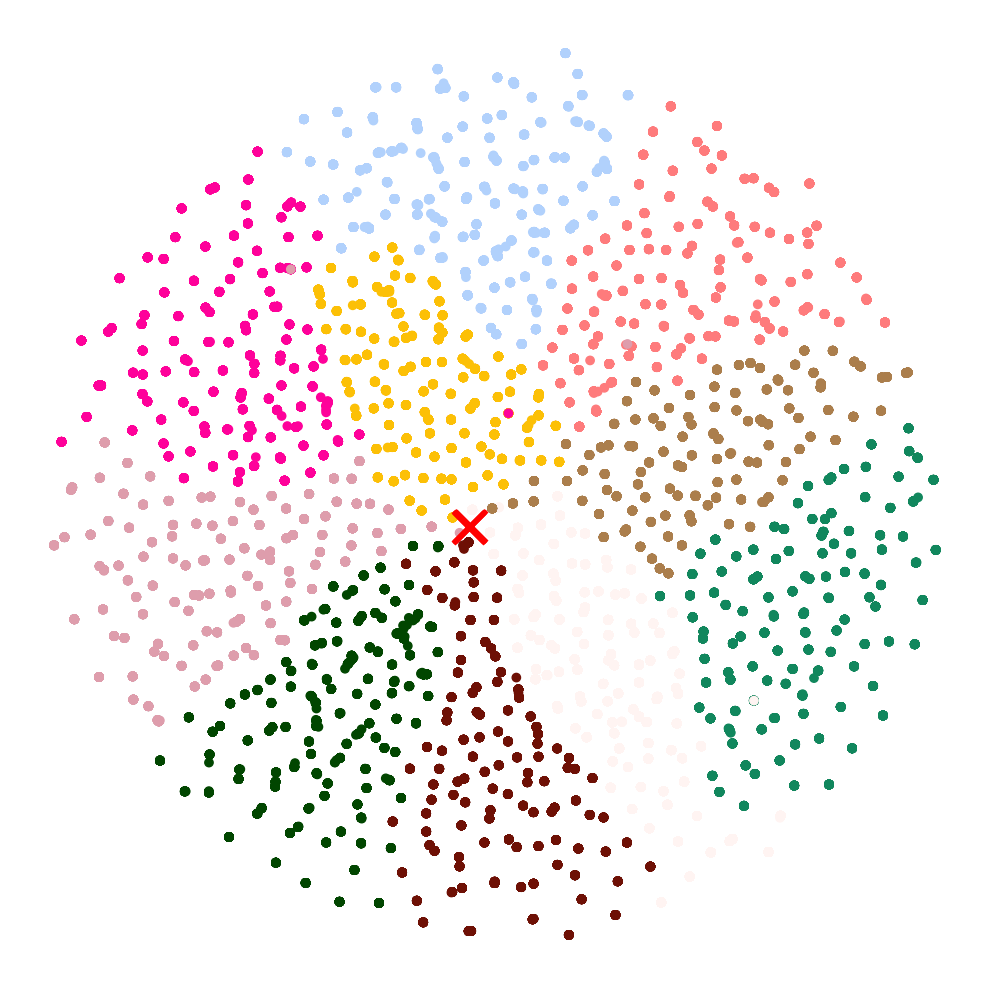

In [12]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)